In [1]:
#Setup and Data Loading
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()

if not (ROOT / "src" / "model_data.py").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from model_data import (
    load_features,
    cv_folds,
    cv_report,
    climatology_baseline,
    TARGET
)

OUTPUT = ROOT / "outputs" / "baseline"
OUTPUT.mkdir(parents=True, exist_ok=True)

print("Shared framework loaded successfully")

Shared framework loaded successfully


In [2]:
feb_df = load_features("feb1", source="csv")
mar_df = load_features("mar1", source="csv")

print("February:", feb_df.shape)
print("March:", mar_df.shape)

Loaded model_features_feb1 from data/model/ CSV: 4,365 rows
Loaded model_features_mar1 from data/model/ CSV: 4,365 rows
February: (4365, 33)
March: (4365, 36)


In [3]:
#Model Definition: 30-Year Climatology
MIN_HISTORY = 10
LOOKBACK_YEARS = 30

def climatology_30yr(train_df, val_df):
    predictions = []

    for row in val_df.itertuples(index=False):

        history = train_df[
            train_df["bloom_year"].between(
                row.bloom_year - LOOKBACK_YEARS,
                row.bloom_year - 1
            )
        ]

        station_history = history[
            history["station_id"] == row.station_id
        ]

        if len(station_history) >= MIN_HISTORY:
            prediction = station_history[TARGET].mean()

        else:
            regional_history = history[
                history["region"] == row.region
            ]

            if len(regional_history) > 0:
                prediction = regional_history[TARGET].mean()

            elif len(history) > 0:
                prediction = history[TARGET].mean()

            else:
                prediction = np.nan

        predictions.append(prediction)

    return np.array(predictions)

In [4]:
#Expanding-Window Cross-Validation
#Existing team baseline
all_history = cv_report(
    feb_df,
    climatology_baseline
)

# Our 30-year baseline
feb_30yr = cv_report(
    feb_df,
    climatology_30yr
)

mar_30yr = cv_report(
    mar_df,
    climatology_30yr
)

print("30-YEAR CLIMATOLOGY — FEBRUARY 1")
display(feb_30yr.round(3))

print("\n30-YEAR CLIMATOLOGY — MARCH 1")
display(mar_30yr.round(3))

30-YEAR CLIMATOLOGY — FEBRUARY 1


,fold,n,MAE,RMSE,R2,hit_rate_3d
0,1,148,2.737,3.514,0.909,0.635
1,2,127,3.383,4.393,0.776,0.535
2,3,106,3.618,4.505,0.833,0.500
3,4,98,3.232,3.774,0.851,0.469
4,5,96,6.049,6.679,0.727,0.146
5,mean,575,3.804,4.573,0.819,0.457



30-YEAR CLIMATOLOGY — MARCH 1


,fold,n,MAE,RMSE,R2,hit_rate_3d
0,1,148,2.737,3.514,0.909,0.635
1,2,127,3.383,4.393,0.776,0.535
2,3,106,3.618,4.505,0.833,0.500
3,4,98,3.232,3.774,0.851,0.469
4,5,96,6.049,6.679,0.727,0.146
5,mean,575,3.804,4.573,0.819,0.457


In [5]:
#Model Comparison
metrics = ["MAE", "RMSE", "R2", "hit_rate_3d"]

comparison = pd.DataFrame({
    "Metric": metrics,
    "All_History": [
        all_history.iloc[-1][m] for m in metrics
    ],
    "30_Year": [
        feb_30yr.iloc[-1][m] for m in metrics
    ]
})

display(comparison.round(3))

,Metric,All_History,30_Year
0,MAE,3.956,3.804
1,RMSE,4.687,4.573
2,R2,0.804,0.819
3,hit_rate_3d,0.440,0.457


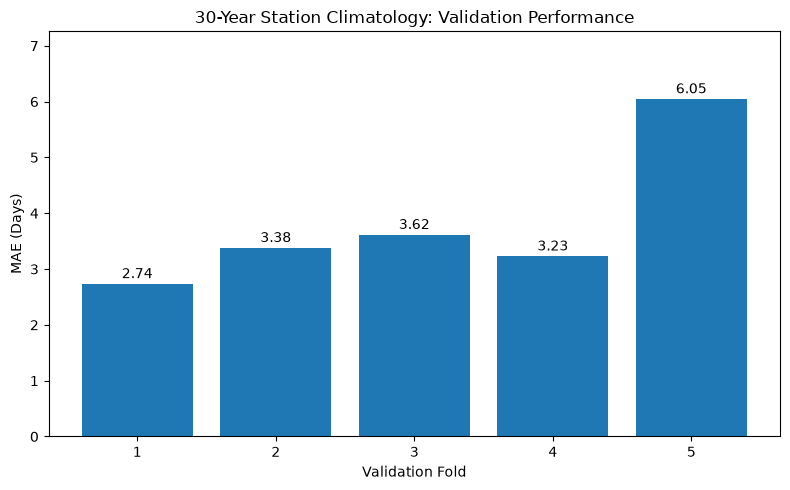

In [6]:
fold_data = feb_30yr[
    feb_30yr["fold"] != "mean"
].copy()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    fold_data["fold"].astype(str),
    fold_data["MAE"]
)

for bar, value in zip(bars, fold_data["MAE"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{value:.2f}",
        ha="center"
    )

plt.xlabel("Validation Fold")
plt.ylabel("MAE (Days)")
plt.title("30-Year Station Climatology: Validation Performance")

plt.ylim(0, fold_data["MAE"].max() * 1.2)
plt.tight_layout()
plt.show()

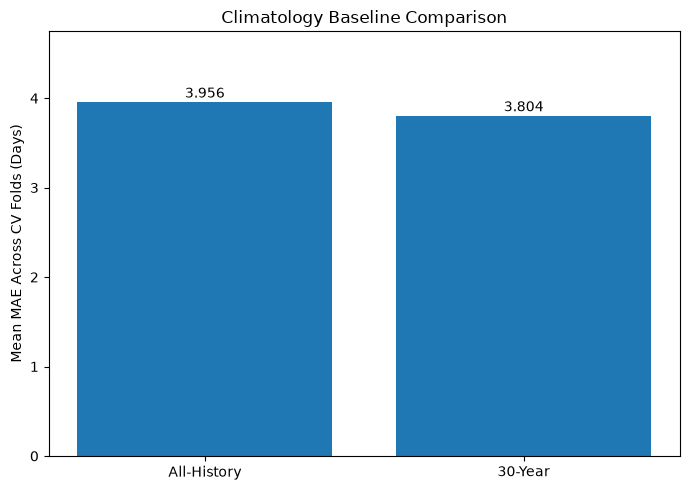

In [7]:
mae_values = comparison[
    comparison["Metric"] == "MAE"
]

models = ["All-History", "30-Year"]

values = [
    mae_values["All_History"].iloc[0],
    mae_values["30_Year"].iloc[0]
]

plt.figure(figsize=(7, 5))

bars = plt.bar(models, values)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f"{value:.3f}",
        ha="center"
    )

plt.ylabel("Mean MAE Across CV Folds (Days)")
plt.title("Climatology Baseline Comparison")

plt.ylim(0, max(values) * 1.2)
plt.tight_layout()
plt.show()

In [8]:
feb_30yr.to_csv(
    OUTPUT / "climatology_30yr_feb_cv.csv",
    index=False
)

mar_30yr.to_csv(
    OUTPUT / "climatology_30yr_mar_cv.csv",
    index=False
)

all_history.to_csv(
    OUTPUT / "climatology_all_history_cv.csv",
    index=False
)

comparison.to_csv(
    OUTPUT / "climatology_comparison.csv",
    index=False
)

print("Station climatology results saved successfully!")

Station climatology results saved successfully!


In [9]:

# Export individual 30-year climatology predictions

climatology_predictions = []

for fold_no, train_df, val_df in cv_folds(feb_df):

    predictions = climatology_30yr(train_df, val_df)

    fold_output = pd.DataFrame({
        "fold": fold_no,
        "station_id": val_df["station_id"].values,
        "year": val_df["bloom_year"].values,
        "actual_doy": val_df[TARGET].values,
        "predicted_doy": predictions
    })

    climatology_predictions.append(fold_output)

climatology_predictions = pd.concat(
    climatology_predictions,
    ignore_index=True
)

print("Climatology predictions:", len(climatology_predictions))
print("Missing predictions:",
      climatology_predictions["predicted_doy"].isna().sum())

climatology_predictions.to_csv(
    OUTPUT / "climatology_30yr_cv_predictions.csv",
    index=False
)

display(climatology_predictions.head())


Climatology predictions: 575
Missing predictions: 0


,fold,station_id,year,actual_doy,predicted_doy
0,1,412,2005,136,128.033333
1,1,423,2005,140,131.800000
2,1,428,2005,132,125.517241
3,1,430,2005,125,125.666667
4,1,433,2005,140,134.200000


In [11]:

import pandas as pd

# Load saved regional temperature-rule predictions
regional = pd.read_csv(
    OUTPUT / "temperature_regional_cv_predictions.csv"
)

# Load saved climatology predictions
clim_predictions = pd.read_csv(
    OUTPUT / "climatology_30yr_cv_predictions.csv"
)

# Ensure station IDs have matching data types
regional["station_id"] = regional["station_id"].astype(str)
clim_predictions["station_id"] = (
    clim_predictions["station_id"].astype(str)
)

print("Regional predictions:", regional.shape)
print("Climatology predictions:", clim_predictions.shape)

paired = regional[
    regional["forecast_date"] == "feb1"
][
    ["fold", "station_id", "year", "actual_doy", "predicted_doy"]
].merge(
    clim_predictions[
        ["fold", "station_id", "year", "actual_doy", "predicted_doy"]
    ],
    on=["fold", "station_id", "year"],
    suffixes=("_regional", "_climatology"),
    validate="one_to_one"
)

assert (
    paired["actual_doy_regional"]
    == paired["actual_doy_climatology"]
).all(), "Target mismatch detected"

paired["AE_regional"] = (
    paired["predicted_doy_regional"]
    - paired["actual_doy_regional"]
).abs()

paired["AE_climatology"] = (
    paired["predicted_doy_climatology"]
    - paired["actual_doy_climatology"]
).abs()

paired["AE_difference"] = (
    paired["AE_climatology"]
    - paired["AE_regional"]
)

print("Paired observations:", len(paired))

print(
    "Regional model better:",
    (paired["AE_difference"] > 0).sum()
)

print(
    "Climatology better:",
    (paired["AE_difference"] < 0).sum()
)

print(
    "Equal absolute error:",
    (paired["AE_difference"] == 0).sum()
)

print(
    "Mean paired MAE improvement:",
    paired["AE_difference"].mean().round(3)
)

display(paired.head())


Regional predictions: (1150, 12)
Climatology predictions: (575, 5)
Paired observations: 575
Regional model better: 233
Climatology better: 337
Equal absolute error: 5
Mean paired MAE improvement: -0.529


,fold,station_id,year,actual_doy_regional,predicted_doy_regional,actual_doy_climatology,predicted_doy_climatology,AE_regional,AE_climatology,AE_difference
0,1,412,2005,136,129,136,128.033333,7,7.966667,0.966667
1,1,423,2005,140,134,140,131.800000,6,8.200000,2.200000
2,1,428,2005,132,124,132,125.517241,8,6.482759,-1.517241
3,1,430,2005,125,123,125,125.666667,2,0.666667,-1.333333
4,1,433,2005,140,138,140,134.200000,2,5.800000,3.800000


In [14]:
# ============================================================
# REGIONAL THRESHOLD IMPROVEMENT
# ============================================================

# Load saved national predictions
national = pd.read_csv(
    OUTPUT / "temperature_national_cv_predictions.csv"
)

# Regional predictions already loaded
regional = pd.read_csv(
    OUTPUT / "temperature_regional_cv_predictions.csv"
)

# Standardize station IDs
national["station_id"] = national["station_id"].astype(str)
regional["station_id"] = regional["station_id"].astype(str)

# Match predictions
keys = ["fold", "forecast_date", "station_id", "year"]

paired_region = regional[
    keys + ["region", "actual_doy", "predicted_doy"]
].merge(
    national[
        keys + ["actual_doy", "predicted_doy"]
    ],
    on=keys,
    suffixes=("_regional", "_national"),
    validate="one_to_one"
)

# Verify matching targets
assert (
    paired_region["actual_doy_regional"]
    == paired_region["actual_doy_national"]
).all(), "Target mismatch detected"

# Calculate absolute errors
paired_region["AE_regional"] = (
    paired_region["predicted_doy_regional"]
    - paired_region["actual_doy_regional"]
).abs()

paired_region["AE_national"] = (
    paired_region["predicted_doy_national"]
    - paired_region["actual_doy_national"]
).abs()

# Calculate regional improvements
regional_improvement = (
    paired_region
    .groupby(["region", "forecast_date"])
    .agg(
        N=("AE_regional", "count"),
        National_MAE=("AE_national", "mean"),
        Regional_MAE=("AE_regional", "mean")
    )
    .reset_index()
)

regional_improvement["MAE_reduction"] = (
    regional_improvement["National_MAE"]
    - regional_improvement["Regional_MAE"]
)

display(regional_improvement.round(3))
paired.to_csv(
    OUTPUT / "climatology_vs_regional_paired_errors.csv",
    index=False
)

regional_improvement.to_csv(
    OUTPUT / "regional_threshold_improvement.csv",
    index=False
)

print("Baseline handover outputs saved!")

,region,forecast_date,N,National_MAE,Regional_MAE,MAE_reduction
0,Chubu,feb1,110,4.191,3.591,0.600
1,Chubu,mar1,110,3.991,3.700,0.291
2,Chugoku,feb1,61,3.148,3.115,0.033
3,Chugoku,mar1,61,3.361,3.311,0.049
4,Hokkaido,feb1,35,9.743,5.114,4.629
5,Hokkaido,mar1,35,9.229,5.371,3.857
6,Kansai,feb1,89,3.191,3.371,-0.180
7,Kansai,mar1,89,3.764,3.663,0.101
8,Kanto,feb1,81,4.716,5.383,-0.667
9,Kanto,mar1,81,4.852,5.185,-0.333


Baseline handover outputs saved!


In [15]:
print("Saved files:")

for file in OUTPUT.glob("*.csv"):
    print(file.name)

Saved files:
baseline_validation_comparison.csv
climatology_30yr_cv_metrics.csv
climatology_30yr_cv_predictions.csv
climatology_30yr_feb_cv.csv
climatology_30yr_mar_cv.csv
climatology_all_history_cv.csv
climatology_comparison.csv
climatology_vs_regional_paired_errors.csv
final_baseline_cv_comparison.csv
regional_threshold_improvement.csv
shared_data_verification.csv
temperature_national_cv_metrics.csv
temperature_national_cv_predictions.csv
temperature_regional_cv_metrics.csv
temperature_regional_cv_predictions.csv


In [16]:

from IPython.display import display, Markdown

summary = """
# Key Findings — Baseline Model Benchmarking

## 1. Overall Model Performance

Five-fold expanding-window cross-validation (2005–2014)
was used to evaluate the baseline models.

| Model | MAE | RMSE | R² | ±3-Day Hit Rate |
|---|---:|---:|---:|---:|
| **30-Year Station Climatology** | **3.804** | **4.573** | **0.819** | 45.72% |
| National Temperature Rule — Feb 1 | 4.818 | 6.304 | 0.632 | 45.33% |
| Regional Temperature Rule — Feb 1 | 4.287 | 5.406 | 0.743 | **48.48%** |
| National Temperature Rule — Mar 1 | 4.975 | 6.527 | 0.607 | 44.71% |
| Regional Temperature Rule — Mar 1 | 4.383 | 5.532 | 0.726 | 48.23% |

*Results are unweighted averages across five validation folds,
not final test results.*

---

## 2. Key Findings

### Finding 1 — Station Climatology Achieved the Lowest Error

The 30-year Station Climatology achieved the lowest MAE
(3.804 days), RMSE (4.573 days), and highest R² (0.819).

This establishes historical station-level bloom timing
as a strong benchmark for the advanced regression models.

### Finding 2 — Regional Temperature Calibration Improved Accuracy

Compared with the national temperature threshold,
regional calibration reduced MAE by:

- **11.0% for February 1**
- **11.9% for March 1**

This suggests that geographic differences in temperature
accumulation are important for full-bloom prediction.

### Finding 3 — Regional Improvements Were Uneven

The largest improvements occurred in:

- **Hokkaido:** 4.629-day MAE reduction (Feb 1)
- **Tohoku:** 1.867-day MAE reduction (Feb 1)

However, regional calibration increased prediction errors
in Kanto and Shikoku for both forecast dates.

Therefore, regional thresholds are not universally superior.

### Finding 4 — March 1 Did Not Consistently Outperform February 1

Despite incorporating observed February temperatures,
the regional March 1 model achieved a higher MAE
(4.383 days) than February 1 (4.287 days).

Additional weather information did not automatically
improve accuracy under the current forecasting assumptions.

### Finding 5 — Model Preference Depends on the Metric

- **Lowest MAE:** 30-Year Station Climatology (3.804 days)
- **Highest ±3-day hit rate:** Regional February 1 (48.48%)

The best benchmark therefore depends on whether the
business prioritizes average prediction error or
the proportion of forecasts within three days.

---

## 3. Model Limitations

- Station Climatology cannot capture unusual current-season weather.
- Future temperatures are estimated using historical daily averages.
- Regional thresholds cannot fully represent local microclimates.
- Regional calibration does not improve accuracy in every region.
- Leap-year handling and forecast-cutoff-safe weather imputation
  require final verification.
- Model configurations were compared using validation data;
  independent test performance has not yet been assessed.

---

## 4. Conclusion

**The 30-year Station Climatology is retained as the primary
historical benchmark because it achieved the lowest validation MAE.**

**The regionally calibrated temperature rule is retained as
the preferred temperature-based benchmark.**

Although regional calibration improved the national
temperature-rule approach, the 30-year climatology
remained more accurate on average.

These results establish the benchmarks for evaluating
the team's advanced regression models.

**The 2015–2025 test period remains untouched until
the team's final champion-model evaluation.**
"""

display(Markdown(summary))



# Key Findings — Baseline Model Benchmarking

## 1. Overall Model Performance

Five-fold expanding-window cross-validation (2005–2014)
was used to evaluate the baseline models.

| Model | MAE | RMSE | R² | ±3-Day Hit Rate |
|---|---:|---:|---:|---:|
| **30-Year Station Climatology** | **3.804** | **4.573** | **0.819** | 45.72% |
| National Temperature Rule — Feb 1 | 4.818 | 6.304 | 0.632 | 45.33% |
| Regional Temperature Rule — Feb 1 | 4.287 | 5.406 | 0.743 | **48.48%** |
| National Temperature Rule — Mar 1 | 4.975 | 6.527 | 0.607 | 44.71% |
| Regional Temperature Rule — Mar 1 | 4.383 | 5.532 | 0.726 | 48.23% |

*Results are unweighted averages across five validation folds,
not final test results.*

---

## 2. Key Findings

### Finding 1 — Station Climatology Achieved the Lowest Error

The 30-year Station Climatology achieved the lowest MAE
(3.804 days), RMSE (4.573 days), and highest R² (0.819).

This establishes historical station-level bloom timing
as a strong benchmark for the advanced regression models.

### Finding 2 — Regional Temperature Calibration Improved Accuracy

Compared with the national temperature threshold,
regional calibration reduced MAE by:

- **11.0% for February 1**
- **11.9% for March 1**

This suggests that geographic differences in temperature
accumulation are important for full-bloom prediction.

### Finding 3 — Regional Improvements Were Uneven

The largest improvements occurred in:

- **Hokkaido:** 4.629-day MAE reduction (Feb 1)
- **Tohoku:** 1.867-day MAE reduction (Feb 1)

However, regional calibration increased prediction errors
in Kanto and Shikoku for both forecast dates.

Therefore, regional thresholds are not universally superior.

### Finding 4 — March 1 Did Not Consistently Outperform February 1

Despite incorporating observed February temperatures,
the regional March 1 model achieved a higher MAE
(4.383 days) than February 1 (4.287 days).

Additional weather information did not automatically
improve accuracy under the current forecasting assumptions.

### Finding 5 — Model Preference Depends on the Metric

- **Lowest MAE:** 30-Year Station Climatology (3.804 days)
- **Highest ±3-day hit rate:** Regional February 1 (48.48%)

The best benchmark therefore depends on whether the
business prioritizes average prediction error or
the proportion of forecasts within three days.

---

## 3. Model Limitations

- Station Climatology cannot capture unusual current-season weather.
- Future temperatures are estimated using historical daily averages.
- Regional thresholds cannot fully represent local microclimates.
- Regional calibration does not improve accuracy in every region.
- Leap-year handling and forecast-cutoff-safe weather imputation
  require final verification.
- Model configurations were compared using validation data;
  independent test performance has not yet been assessed.

---

## 4. Conclusion

**The 30-year Station Climatology is retained as the primary
historical benchmark because it achieved the lowest validation MAE.**

**The regionally calibrated temperature rule is retained as
the preferred temperature-based benchmark.**

Although regional calibration improved the national
temperature-rule approach, the 30-year climatology
remained more accurate on average.

These results establish the benchmarks for evaluating
the team's advanced regression models.

**The 2015–2025 test period remains untouched until
the team's final champion-model evaluation.**


In [17]:

from IPython.display import display, Markdown

summary = """
# Key Findings — 30-Year Station Climatology

## 1. Model Overview

The Station Climatology baseline predicts full-bloom
day of year using each station's historical average
over the preceding 30 calendar years.

### Modelling Assumptions

- Historical window: preceding 30 calendar years.
- Minimum station history: 10 observations.
- Insufficient history: regional mean fallback,
  followed by national mean fallback.
- Training information restricted to permitted
  historical observations within each CV fold.
- Same predictions for February 1 and March 1,
  because current-season weather is not used.

---

## 2. Validation Performance

Five expanding-window CV folds were used to compare
the 30-year climatology with the team's all-history
climatology implementation.

| Metric | All-History | 30-Year |
|---|---:|---:|
| MAE (days) | 3.956 | **3.804** |
| RMSE (days) | 4.687 | **4.573** |
| R² | 0.804 | **0.819** |
| ±3-Day Hit Rate | 44.0% | **45.72%** |

*Results are unweighted five-fold validation averages.*

---

## 3. Key Findings

### Finding 1 — 30-Year Climatology Performed Better

The 30-year baseline achieved lower MAE and RMSE
than the all-history baseline.

MAE decreased from 3.956 to 3.804 days,
an improvement of approximately 3.8%.

This suggests that a more recent historical window
may be more representative of contemporary bloom timing.

### Finding 2 — Strong Geographic Predictive Performance

The 30-year baseline achieved an average fold-level
R² of 0.819.

However, pooled station-level variation can contribute
to high R² values. This does not necessarily imply
equally strong prediction of year-to-year anomalies.

### Finding 3 — Performance Varied Across Validation Folds

The final validation fold (2013–2014) recorded
an MAE of approximately 6.049 days.

This was considerably higher than earlier folds,
highlighting the limitations of relying exclusively
on historical averages.

### Finding 4 — Identical Forecasts for Both Issue Dates

February 1 and March 1 produced identical
climatology predictions.

This is expected because the model does not
incorporate current-year weather observations.

---

## 4. Model Limitations

- Historical averages cannot respond to unusual
  seasonal weather conditions.
- Long-term changes in flowering patterns may
  reduce the relevance of older observations.
- Stations with limited historical records require
  fallback predictions.
- Forecast accuracy varies across validation periods.
- The 10-observation minimum is an implementation
  assumption rather than a team-mandated requirement.

---

## 5. Conclusion

**The 30-year Station Climatology was retained as
the primary historical baseline.**

It achieved a validation MAE of 3.804 days and
a ±3-day hit rate of approximately 45.72%.

Its performance provides a benchmark for evaluating
the adapted temperature rule and the team's
advanced regression models.

**Final testing on 2015–2025 remains pending.**
"""

display(Markdown(summary))



# Key Findings — 30-Year Station Climatology

## 1. Model Overview

The Station Climatology baseline predicts full-bloom
day of year using each station's historical average
over the preceding 30 calendar years.

### Modelling Assumptions

- Historical window: preceding 30 calendar years.
- Minimum station history: 10 observations.
- Insufficient history: regional mean fallback,
  followed by national mean fallback.
- Training information restricted to permitted
  historical observations within each CV fold.
- Same predictions for February 1 and March 1,
  because current-season weather is not used.

---

## 2. Validation Performance

Five expanding-window CV folds were used to compare
the 30-year climatology with the team's all-history
climatology implementation.

| Metric | All-History | 30-Year |
|---|---:|---:|
| MAE (days) | 3.956 | **3.804** |
| RMSE (days) | 4.687 | **4.573** |
| R² | 0.804 | **0.819** |
| ±3-Day Hit Rate | 44.0% | **45.72%** |

*Results are unweighted five-fold validation averages.*

---

## 3. Key Findings

### Finding 1 — 30-Year Climatology Performed Better

The 30-year baseline achieved lower MAE and RMSE
than the all-history baseline.

MAE decreased from 3.956 to 3.804 days,
an improvement of approximately 3.8%.

This suggests that a more recent historical window
may be more representative of contemporary bloom timing.

### Finding 2 — Strong Geographic Predictive Performance

The 30-year baseline achieved an average fold-level
R² of 0.819.

However, pooled station-level variation can contribute
to high R² values. This does not necessarily imply
equally strong prediction of year-to-year anomalies.

### Finding 3 — Performance Varied Across Validation Folds

The final validation fold (2013–2014) recorded
an MAE of approximately 6.049 days.

This was considerably higher than earlier folds,
highlighting the limitations of relying exclusively
on historical averages.

### Finding 4 — Identical Forecasts for Both Issue Dates

February 1 and March 1 produced identical
climatology predictions.

This is expected because the model does not
incorporate current-year weather observations.

---

## 4. Model Limitations

- Historical averages cannot respond to unusual
  seasonal weather conditions.
- Long-term changes in flowering patterns may
  reduce the relevance of older observations.
- Stations with limited historical records require
  fallback predictions.
- Forecast accuracy varies across validation periods.
- The 10-observation minimum is an implementation
  assumption rather than a team-mandated requirement.

---

## 5. Conclusion

**The 30-year Station Climatology was retained as
the primary historical baseline.**

It achieved a validation MAE of 3.804 days and
a ±3-day hit rate of approximately 45.72%.

Its performance provides a benchmark for evaluating
the adapted temperature rule and the team's
advanced regression models.

**Final testing on 2015–2025 remains pending.**
